# Nutrition5k: exploración del dataset

No entrena nada: lee `data/nutrition5k/` (metadatos, splits oficiales de la vista cenital e imágenes cenitales) y, en la
última parte, las predicciones de un run de `outputs/`. Responde a:

1. Cuántos platos hay en cada partición (train, validación, test) y cuántos tienen imagen cenital.
2. Cómo se distribuyen los cinco objetivos en cada partición.
3. Qué platos tienen etiquetas imposibles o incoherentes.
4. Cuánto pesan esos platos en el PMAE (que divide por la media del split).
5. Dónde se concentra el error de un modelo.
6. Si validación tiene platos casi duplicados de train (escaneos incrementales); el detalle está en
   `incremental_scans.ipynb`.

Las particiones parten del split oficial de la vista cenital (`depth_train_ids.txt` y `depth_test_ids.txt`). La
validación es la misma que usa `train`: `split_validation` sobre los platos de train oficiales, sin los platos de
`excluded_dishes.csv`, apartando grupos de escaneos enteros (10 %, por hash). Hace falta haber ejecutado
`prepare --full`, que descarga las imágenes y ejecuta `preprocess`.

In [1]:
import csv
import os
from pathlib import Path

if Path("/workspace").is_dir():  # RunPod
    os.chdir("/root/thesis-multimodal-health-ai")
elif Path.cwd().parent.parent.name == "notebooks":
    os.chdir("../../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from nutrition5k import load_dataset
from nutrition5k.dataset import OVERHEAD_DIR, SPLIT_FILES, split_validation
from nutrition5k.preprocess import MANUAL_EXCLUSIONS, label_errors

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

ROOT = Path("data/nutrition5k")
TARGETS = {"mass": "g", "calories": "kcal", "fat": "g", "carb": "g", "protein": "g"}
SPLITS = ("train", "val", "test")
SERIES = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
INK, MUTED = "#0b0b0b", "#52514e"
SPLIT_COLORS = dict(zip(SPLITS, SERIES))

In [2]:
def load_dishes(root):
    """One row per dish of both metadata files, with its ingredients as {ingredient id: grams}."""
    rows, names = [], {}
    for cafe in ("cafe1", "cafe2"):
        with open(root / f"metadata/dish_metadata_{cafe}.csv", newline="") as handle:
            for row in csv.reader(handle):
                ingredients = {row[i]: float(row[i + 2]) for i in range(6, len(row), 7)}
                names.update({row[i]: row[i + 1] for i in range(6, len(row), 7)})
                calories, mass, fat, carb, protein = map(float, row[1:6])
                rows.append({
                    "dish_id": row[0], "cafe": cafe, "mass": mass, "calories": calories,
                    "fat": fat, "carb": carb, "protein": protein, "ingredients": ingredients,
                })
    dishes = pd.DataFrame(rows).set_index("dish_id")
    dishes["time"] = dishes.index.str.removeprefix("dish_").astype(int)  # dish ids are Unix timestamps
    return dishes, names


dishes, INGREDIENT_NAMES = load_dishes(ROOT)

# Splits exactly as `train` builds them (validation is held out before dropping dishes without an image).
dataset = load_dataset(ROOT, full=True)
train, validation = split_validation(dataset.train, groups=dataset.groups)
dishes["split"] = "none"  # dishes in the metadata but in neither official overhead split
# Official train dishes in excluded_dishes.csv are in neither train nor validation; excluded test dishes stay in test.
dishes.loc[(ROOT / SPLIT_FILES["train"]).read_text().split(), "split"] = "excluded"
for name, records in (("train", train), ("val", validation), ("test", dataset.test)):
    dishes.loc[[record.dish_id for record in records], "split"] = name
# Every downloaded overhead image, also of the excluded dishes, so they can be shown.
IMAGE = {dish: ROOT / OVERHEAD_DIR / dish / "rgb.png" for dish in dishes.index}
IMAGE = {dish: path for dish, path in IMAGE.items() if path.is_file()}
dishes["image"] = dishes.index.isin(list(IMAGE))
print(f"{len(dishes)} dishes in the metadata, {len(IMAGE)} with an overhead image in data/")

5006 dishes in the metadata, 3262 with an overhead image in data/


## 1. Particiones

`excluded` son los platos de train oficiales que `preprocess` deja fuera (no están en train ni en validación); los
excluidos de test siguen en test. `none` son los platos de los metadatos que no están en el split cenital. Los modelos
usan los platos con imagen; los que no la tienen se descartan en train, validación y test. La línea base de la media se
evalúa sobre todos los platos de test.

In [3]:
partitions = dishes.pivot_table(
    index="split", columns="image", values="mass", aggfunc="size", fill_value=0
).rename(columns={True: "with image", False: "without image"})
partitions["total"] = partitions.sum(axis=1)
partitions["share (%)"] = (100 * partitions["total"] / partitions["total"].sum()).round(1)
display(partitions.reindex([*SPLITS, "excluded", "none"]))
display(pd.crosstab(dishes["split"], dishes["cafe"]))

image,without image,with image,total,share (%)
split,,,,
train,3,2475,2478,49.5
val,0,278,278,5.6
test,0,507,507,10.1
excluded,0,2,2,0.0
none,1741,0,1741,34.8


cafe,cafe1,cafe2
split,,
excluded,2,0
none,1503,238
test,507,0
train,2478,0
val,278,0


Cada plato tiene una sola imagen cenital. El recorte fijo (`CROP_BOX`) supone que todas miden 640×480; la tabla da, por
partición, los tamaños encontrados y cuántos platos tienen también la profundidad (`depth_raw.png`, que los modelos
todavía no usan).

In [4]:
used = dishes[dishes["image"] & dishes["split"].isin([*SPLITS, "excluded"])].copy()
used["size"] = ["{}x{}".format(*Image.open(IMAGE[dish]).size) for dish in used.index]
used["depth"] = [(IMAGE[dish].parent / "depth_raw.png").is_file() for dish in used.index]
used.groupby("split").agg(
    dishes=("size", "size"), sizes=("size", lambda sizes: ", ".join(sorted(set(sizes)))), with_depth=("depth", "sum")
).reindex([*SPLITS, "excluded"])

,dishes,sizes,with_depth
split,,,
train,2475,640x480,2474
val,278,640x480,278
test,507,640x480,507
excluded,2,640x480,2


## 2. Distribución de los objetivos por partición

El PMAE divide el MAE por la **media del split**, así que conviene que las medias se parezcan y vigilar los máximos:
un solo plato extremo mueve mucho la media y el error.

In [5]:
summary = dishes[dishes["split"].isin(SPLITS)].groupby("split")[list(TARGETS)].agg(
    ["mean", "median", "std", lambda values: values.quantile(0.99), "max"]
).rename(columns={"<lambda_0>": "p99"}, level=1)
summary.reindex(SPLITS).round(1).T

split             train     val    test
mass     mean     216.9   216.2   198.5
         median   178.0   185.5   161.0
         std      153.9   154.4   151.7
         p99      701.4   619.3   684.1
         max      962.0  1102.0   871.0
calories mean     252.5   261.5   255.5
         median   205.8   229.2   226.0
         std      210.3   202.5   212.2
         p99      918.4   762.9   919.0
         max     1324.1  1159.0  1050.5
fat      mean      12.6    13.3    12.8
         median     8.8    10.9     8.4
         std       13.5    12.5    14.2
         p99       59.9    44.4    65.3
         max      106.3    73.2    84.2
carb     mean      19.1    18.0    19.7
         median    15.4    15.3    15.4
         std       15.8    15.4    17.4
         p99       67.1    73.0    73.9
         max      100.7   101.3    85.8
protein  mean      17.9    19.4    17.5
         median    11.4    14.8    11.4
         std       20.1    21.3    19.0
         p99       92.1    87.9    78.1
         max      147.5   108.7    85.3

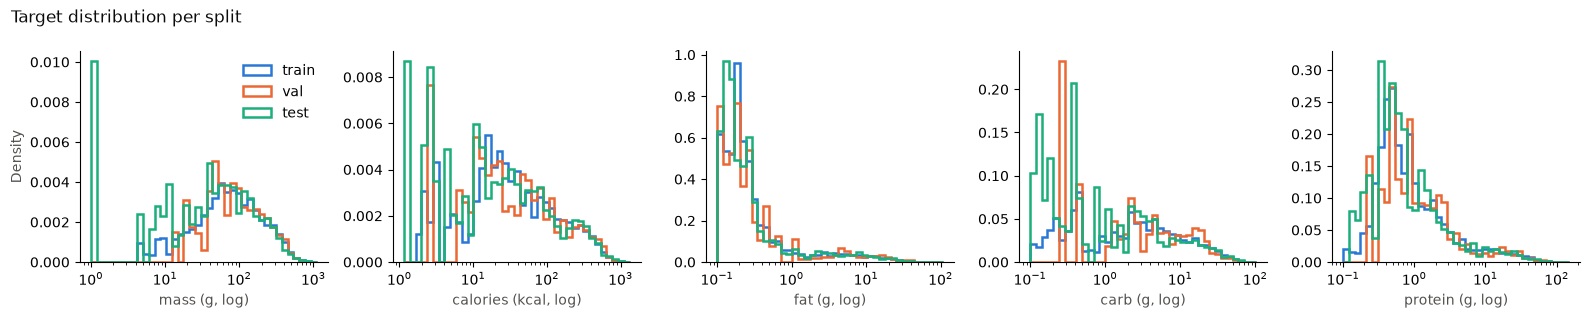

In [6]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(16, 3.2))
for ax, (target, unit) in zip(axes, TARGETS.items()):
    values = dishes.loc[dishes["split"].isin(SPLITS), target]
    bins = np.logspace(np.log10(max(values[values > 0].min(), 0.1)), np.log10(values.max()), 40)
    for split in SPLITS:
        ax.hist(dishes.loc[dishes["split"] == split, target], bins=bins, density=True, histtype="step",
                linewidth=1.8, color=SPLIT_COLORS[split], label=split)
    ax.set_xscale("log")
    ax.set_xlabel(f"{target} ({unit}, log)", color=MUTED)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Density", color=MUTED)
axes[0].legend(frameon=False)
fig.suptitle("Target distribution per split", x=0.01, ha="left", color=INK)
plt.tight_layout()
plt.show()

### Platos con muy poca masa

Test tiene más platos ligeros que train y validación. La tabla da, por partición, la proporción de platos por debajo de
cada masa; debajo, la imagen cenital de cada plato de test con menos de `LIGHT_MASS` gramos, de menor a mayor. Con tan
poca masa, unos gramos de error son un porcentaje grande de error para ese plato (aunque el PMAE divide por la media del
split, no por la masa de cada plato).

In [7]:
def show_dishes(dish_ids, title, columns=4):
    """Overhead image of each dish with its labels."""
    dish_ids = [dish for dish in dish_ids if dish in IMAGE]
    if not dish_ids:
        print("no images for these dishes in data/")
        return
    rows = -(-len(dish_ids) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(3.6 * columns, 3.6 * rows), squeeze=False)
    for ax, dish in zip(axes.flat, dish_ids):
        ax.imshow(Image.open(IMAGE[dish]))
        labels = dishes.loc[dish]
        ax.set_title(f"{dish} ({labels['split']})", loc="left", color=INK, fontsize=9)
        ax.set_xlabel("\n".join(f"{target}: {labels[target]:.0f} {unit}" for target, unit in TARGETS.items()),
                      color=MUTED, fontsize=8, loc="left")
        ax.set_xticks([]), ax.set_yticks([])
    for ax in axes.flat[len(dish_ids):]:
        ax.axis("off")
    fig.suptitle(title, x=0.01, ha="left", color=INK)
    plt.tight_layout()
    plt.show()

,< 10 g (%),< 20 g (%),< 30 g (%),< 50 g (%)
split,,,,
train,0.4,1.5,3.3,8.2
val,0.0,0.4,2.9,8.6
test,1.0,3.0,5.9,12.4


15 test dishes under 20 g (0 without an image are not shown)


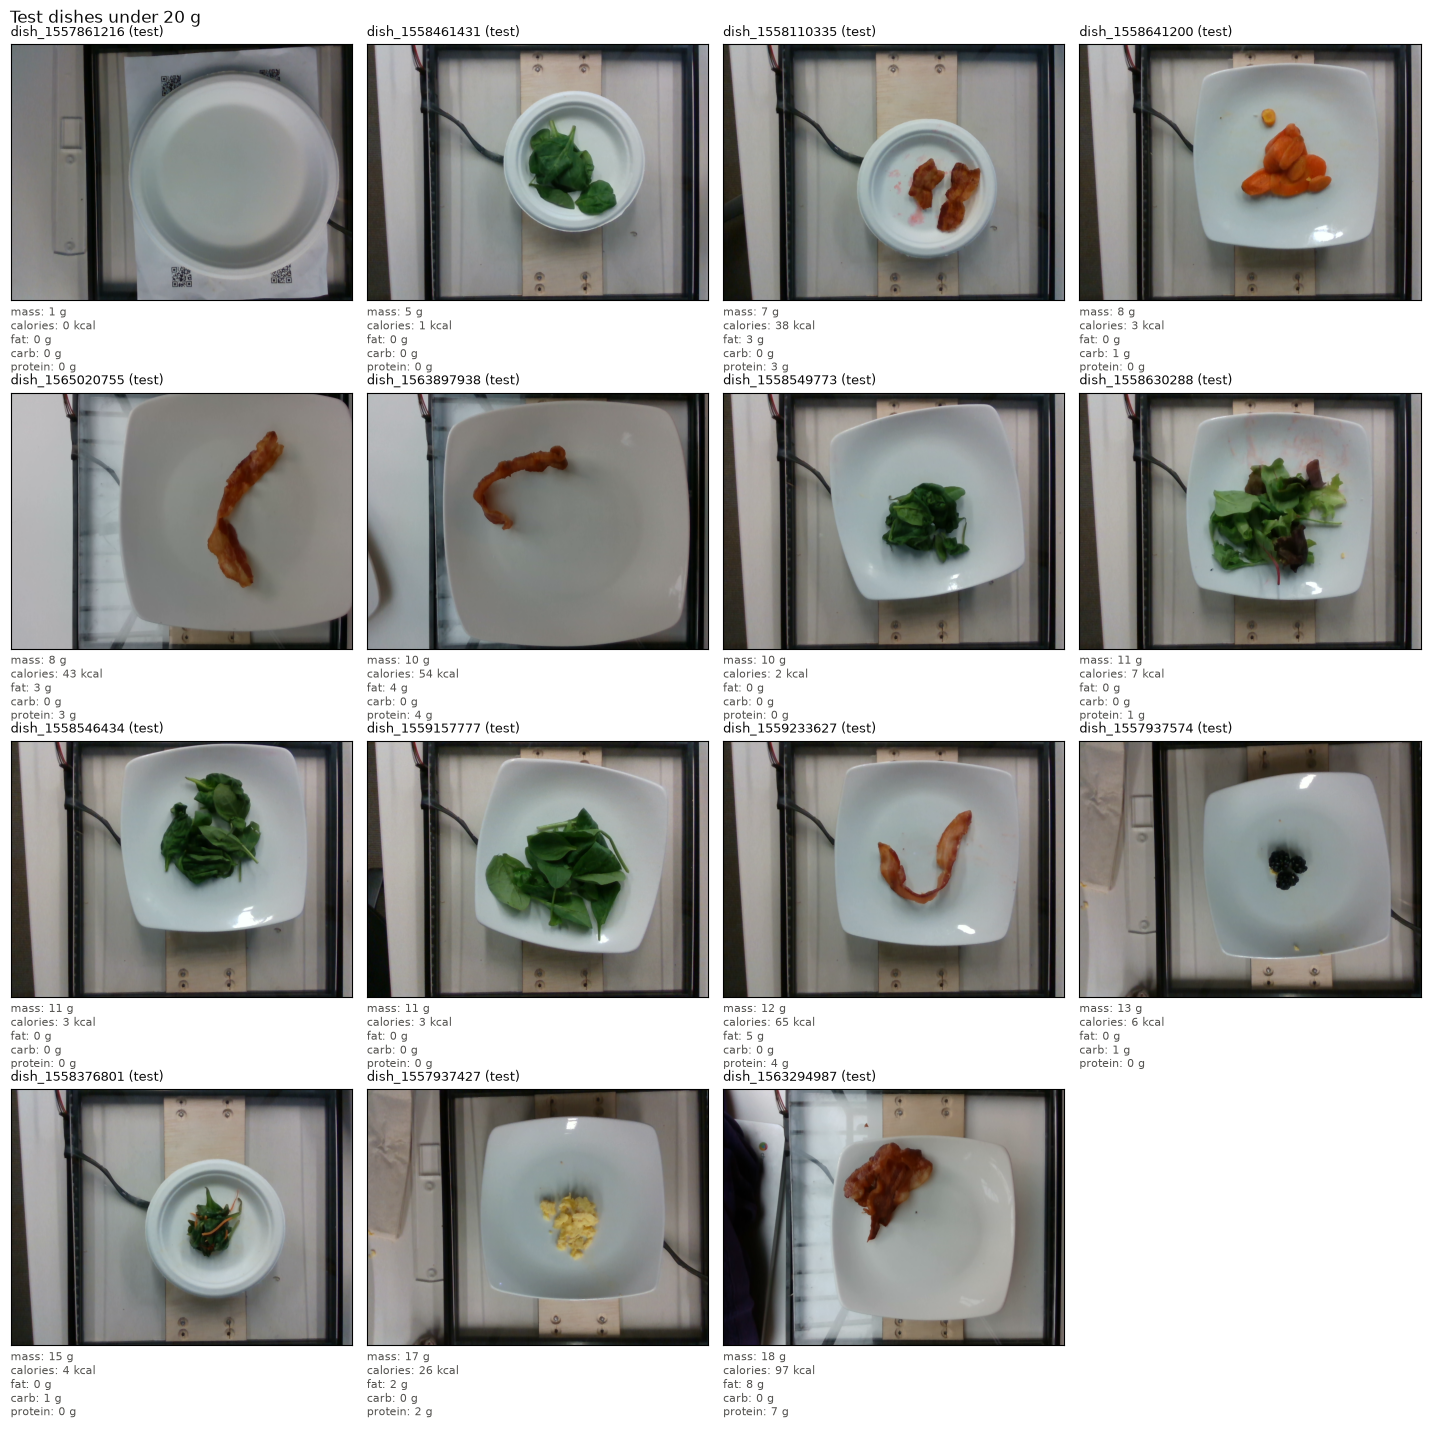

In [8]:
LIGHT_MASS = 20  # g

labelled = dishes[dishes["split"].isin(SPLITS)]
display(pd.DataFrame({
    f"< {limit} g (%)": labelled.groupby("split")["mass"].apply(lambda mass: 100 * (mass < limit).mean())
    for limit in (10, 20, 30, 50)
}).reindex(SPLITS).round(1))

light = labelled[(labelled["split"] == "test") & (labelled["mass"] < LIGHT_MASS)].sort_values("mass")
print(f"{len(light)} test dishes under {LIGHT_MASS} g ({(~light['image']).sum()} without an image are not shown)")
show_dishes(list(light.index), f"Test dishes under {LIGHT_MASS} g")

## 3. Platos con etiquetas sospechosas

Reglas de `nutrition5k.preprocess` (las mismas con las que `preprocess` escribe `excluded_dishes.csv`; cada una es
una comprobación física o de coherencia interna de los metadatos, no una opinión):

- la suma de gramos de los ingredientes no coincide con la masa total (fuera de ±10 %);
- más de 9 kcal/g, más densidad energética que la grasa pura, imposible;
- un solo ingrediente pesa más de 1.5 kg (la mediana de un plato entero es ~145 g en todos los metadatos).

Solo se informa (no excluye): platos con 0 kcal. `excluded_dishes.csv` añade a mano `MANUAL_EXCLUSIONS` (un plato cuya
foto muestra un móvil, no comida), que estas reglas no detectan.

Además se muestra la comprobación de Atwater, 9·grasa + 4·carbohidratos + 4·proteína frente a las calorías: es aproximada
(no cuenta alcohol ni fibra), así que solo sirve como señal.

In [9]:
reasons = pd.Series(label_errors(ROOT), dtype=str).reindex(dishes.index)
checks = pd.DataFrame({
    "mass mismatch": reasons.str.contains("total mass", na=False),
    "> 9 kcal/g": reasons.str.contains("kcal/g", na=False),
    "ingredient > 1500 g": reasons.str.contains("ingredient over", na=False),
    "excluded (any rule)": reasons.notna(),
    "zero calories": dishes["calories"] == 0,
})
atwater = (9 * dishes["fat"] + 4 * dishes["carb"] + 4 * dishes["protein"]) / dishes["calories"]

print("flagged dishes per rule and split:")
display(checks.groupby(dishes["split"]).sum().reindex([*SPLITS, "excluded", "none"]))
print(f"Atwater ratio (dishes with calories): median {atwater.median():.2f}, "
      f"outside [0.7, 1.3]: {((atwater < 0.7) | (atwater > 1.3)).sum()} dishes")

flagged dishes per rule and split:


,mass mismatch,> 9 kcal/g,ingredient > 1500 g,excluded (any rule),zero calories
split,,,,,
train,0,0,0,0,1
val,0,0,0,0,0
test,0,0,0,0,1
excluded,0,0,1,1,0
none,16,4,9,19,238


Atwater ratio (dishes with calories): median 1.04, outside [0.7, 1.3]: 185 dishes


In [10]:
suspicious = dishes[reasons.notna()].copy()
suspicious["reasons"] = reasons[suspicious.index]
suspicious["ingredient grams"] = suspicious["ingredients"].map(
    lambda ingredients: ", ".join(f"{INGREDIENT_NAMES[key]} {grams:.0f} g" for key, grams in ingredients.items()))
suspicious[["split", "image", *TARGETS, "reasons", "ingredient grams"]].sort_values("split").round(1)

,split,image,mass,calories,fat,carb,protein,reasons,ingredient grams
dish_id,,,,,,,,,
dish_1560974769,excluded,True,3051.0,3943.3,11.0,844.6,83.7,an ingredient over 1500 g,"spinach (raw) 26 g, tortilla chips 2 g, corn 5..."
dish_1551567573,none,False,159.0,9485.8,875.5,506.1,87.8,ingredient grams differ from total mass; more ...,"olives 7974 g, sausage 71 g, ham 49 g"
dish_1551389458,none,False,7974.0,2312.5,23.9,717.7,87.7,an ingredient over 1500 g,lemon 7974 g
dish_1551567508,none,False,7974.0,9170.1,853.2,502.4,63.8,an ingredient over 1500 g,olives 7974 g
dish_1551236159,none,False,248.0,281.7,4.5,22.0,38.4,ingredient grams differ from total mass,"mixed greens 12 g, chicken 118 g, orange 178 g"
dish_1551134208,none,False,272.0,194.3,9.8,17.9,9.6,ingredient grams differ from total mass,"pineapple 89 g, scrambled eggs 87 g, cantaloup..."
dish_1551138237,none,False,7974.0,138.9,1.7,27.5,4.6,ingredient grams differ from total mass,"bread 27 g, tomatoes 67 g, pineapple 89 g"
dish_1551237527,none,False,168.0,226.9,3.0,44.5,7.0,ingredient grams differ from total mass,"broccoli 41 g, noodles 128 g, apple 69 g"
dish_1551232973,none,False,7975.0,107.6,1.4,20.7,5.0,ingredient grams differ from total mass,"bell peppers 35 g, cauliflower 126 g, noodles ..."


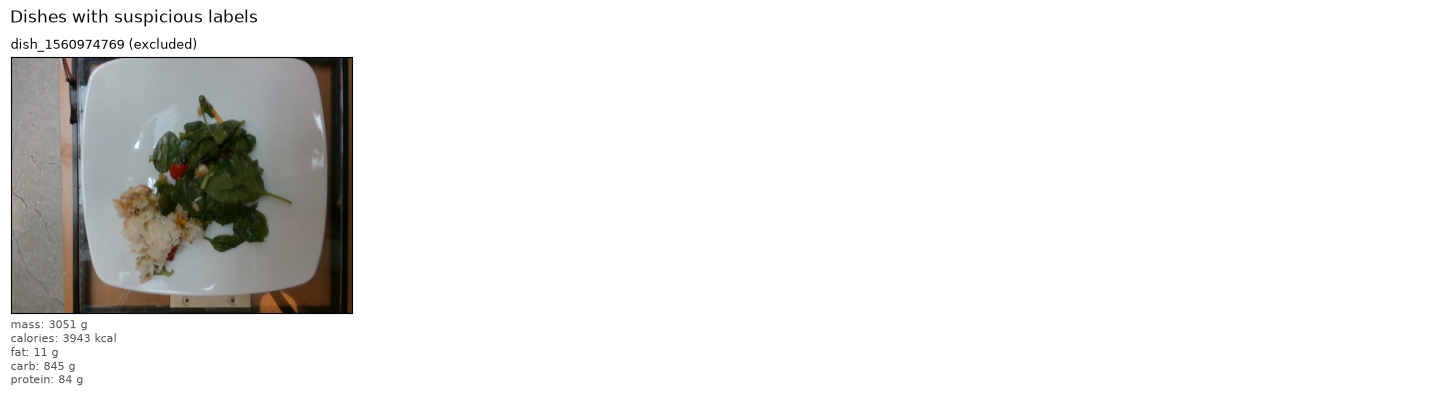

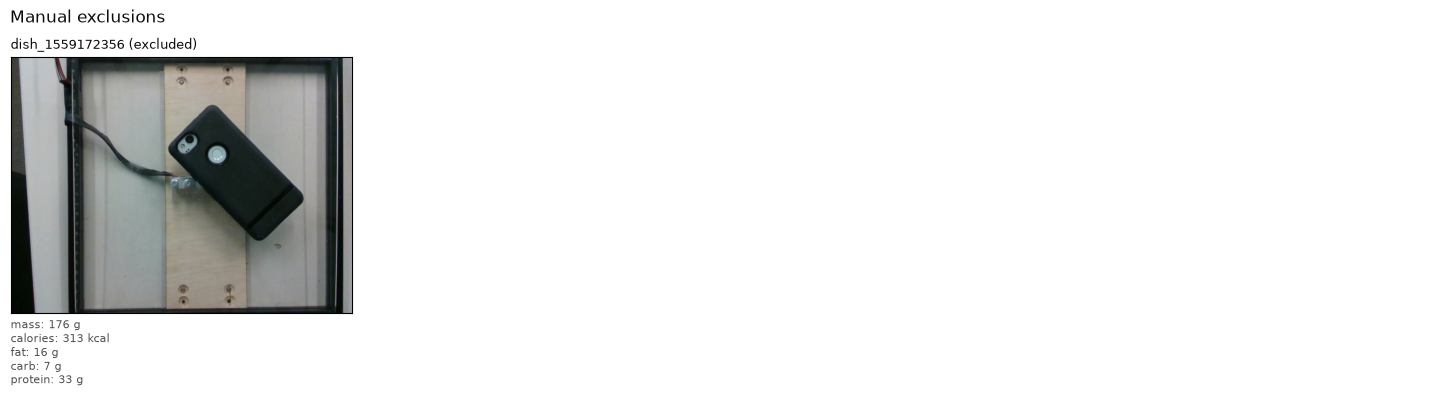

In [11]:
show_dishes(list(suspicious.index), "Dishes with suspicious labels")
show_dishes(list(MANUAL_EXCLUSIONS), "Manual exclusions")

## 4. Peso de los platos sospechosos en el PMAE

Media de cada split con y sin esos platos, y PMAE de la línea base de la media (media de train sin ellos → todos los
platos) con y sin ellos. Aquí los platos de train excluidos cuentan como train, para ver el efecto de quitarlos. Si la
línea base apenas cambia pero un modelo sí, el problema es que el modelo no puede acertar una etiqueta imposible, no que
el split sea más difícil.

In [12]:
def pmae(predicted, truth):
    """PMAE per target, in %: sum of absolute errors / sum of true values (= MAE / mean)."""
    return (predicted - truth).abs().sum() / truth.sum() * 100


# The excluded official train dishes count as train here, so "all" shows the split as it was before preprocess.
labelled = dishes.replace({"split": {"excluded": "train"}})
labelled = labelled[labelled["split"].isin(SPLITS)]
clean = labelled.drop(index=suspicious.index, errors="ignore")
train_mean = clean.loc[clean["split"] == "train", list(TARGETS)].mean()  # as the baseline: fitted without them
rows = []
for split in SPLITS:
    for name, frame in (("all", labelled), ("without suspicious", clean)):
        truth = frame.loc[frame["split"] == split, list(TARGETS)]
        errors = pmae(pd.DataFrame([train_mean] * len(truth), index=truth.index), truth)
        rows.append({"split": split, "dishes": name, "count": len(truth), **truth.mean().add_prefix("mean_").to_dict(),
                     "baseline mean PMAE": errors.mean()})
pd.DataFrame(rows).set_index(["split", "dishes"]).round(1)

count  mean_mass  mean_calories  mean_fat  mean_carb  mean_protein  baseline mean PMAE
split dishes                                                                                                    
train all                  2480      218.0          254.1      12.6       19.5          17.9                71.3
      without suspicious   2479      216.9          252.6      12.6       19.1          17.9                71.2
val   all                   278      216.2          261.5      13.3       18.0          19.4                67.3
      without suspicious    278      216.2          261.5      13.3       18.0          19.4                67.3
test  all                   507      198.5          255.5      12.8       19.7          17.5                73.2
      without suspicious    507      198.5          255.5      12.8       19.7          17.5                73.2

## 5. Dónde se concentra el error de un modelo

Lee `predictions_val.csv` y `predictions.csv` de un run. El error de un plato es la media, sobre los cinco objetivos, de
|error| / media del objetivo en ese split (como el PMAE). Compara la mediana (plato típico) con la cola (peores 5 %),
y recalcula el mean PMAE de test quitando los platos sospechosos o los peores.

In [13]:
# Cualquier run terminado: `train` exige `preprocess`, así que la fila "val" usa la misma validación que el resto del
# notebook. Test incluye los platos excluidos (se evalúan aparte en "without suspicious").
RUN = Path("outputs/mobilenet/full/v4s/v4s-ft_all-single-h512-224-full-s0")
TARGET_COLUMNS = {f"total_{target}": target for target in TARGETS}


def dish_errors(path):
    """Predictions, labels and per-dish error (worst first) of one predictions file."""
    predicted = pd.read_csv(path).set_index("dish_id").rename(columns=TARGET_COLUMNS)[list(TARGETS)]
    truth = dishes.loc[predicted.index, list(TARGETS)]
    return predicted, truth, ((predicted - truth).abs() / truth.mean()).mean(axis=1).sort_values(ascending=False)


errors = {}
if (RUN / "predictions.csv").is_file():
    rows = []
    for split, file in (("val", "predictions_val.csv"), ("test", "predictions.csv")):
        predicted, truth, error = dish_errors(RUN / file)
        errors[split] = error
        rows.append({
            "split": split, "dishes": len(error), "mean PMAE": pmae(predicted, truth).mean(),
            "median dish error (%)": 100 * error.median(),
            "worst 5% share of error": error.head(len(error) // 20).sum() / error.sum(),
            "mean PMAE without suspicious": pmae(predicted.drop(index=suspicious.index, errors="ignore"),
                                                 truth.drop(index=suspicious.index, errors="ignore")).mean(),
            "mean PMAE without worst 3": pmae(predicted.drop(index=error.index[:3]), truth.drop(index=error.index[:3])).mean(),
        })
    display(pd.DataFrame(rows).set_index("split").round(2))
else:
    print(f"no predictions in {RUN}")

no predictions in outputs/mobilenet/full/v4s/v4s-ft_all-single-h512-224-full-s0


In [14]:
if errors:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for split, error in errors.items():
        ax.plot(np.arange(1, len(error) + 1) / len(error) * 100, error.cumsum() / error.sum() * 100,
                color=SPLIT_COLORS[split], linewidth=2, label=split)
    ax.set_xlabel("Worst dishes (% of the split)", color=MUTED)
    ax.set_ylabel("Share of the total error (%)", color=MUTED)
    ax.set_title("How concentrated the error is", loc="left", color=INK)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#e6e6e3", linewidth=0.8)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()
    show_dishes(list(errors["test"].index[:8]), f"{RUN.name}: test dishes with the largest error")

## 6. Platos casi duplicados entre particiones

Nutrition5k escanea el mismo plato varias veces mientras se le añaden ingredientes, y los ids son marcas de tiempo.
Para cada plato de validación y de test: segundos hasta el plato de train más cercano en el tiempo. Si validación
tiene muchos vecinos a pocos segundos y test no, validación contiene variantes de platos de train y sale optimista.
La detección de grupos y la validación por grupos están en `incremental_scans.ipynb`.

,median gap (s),within 60 s (%),within 120 s (%)
val,258.5,12.9,25.5
test,268.0,3.9,17.9


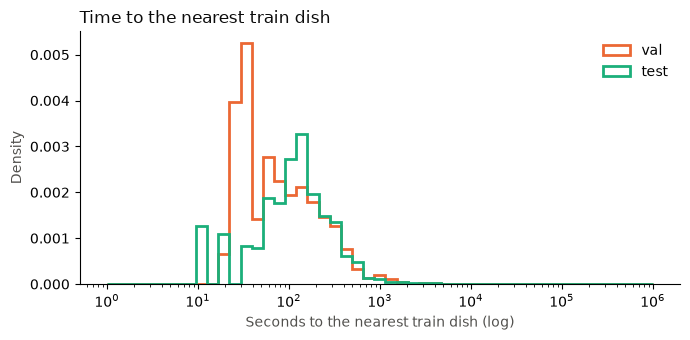

In [15]:
train_times = np.sort(dishes.loc[dishes["split"] == "train", "time"].to_numpy())


def gap_to_train(times):
    position = np.clip(np.searchsorted(train_times, times), 1, len(train_times) - 1)
    return np.minimum(np.abs(times - train_times[position - 1]), np.abs(train_times[position] - times))


gaps = {split: gap_to_train(dishes.loc[dishes["split"] == split, "time"].to_numpy()) for split in ("val", "test")}
display(pd.DataFrame({
    split: {"median gap (s)": np.median(gap), "within 60 s (%)": 100 * (gap <= 60).mean(),
            "within 120 s (%)": 100 * (gap <= 120).mean()}
    for split, gap in gaps.items()
}).T.round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.logspace(0, 6, 50)
for split, gap in gaps.items():
    ax.hist(np.maximum(gap, 1), bins=bins, density=True, histtype="step", linewidth=2, color=SPLIT_COLORS[split], label=split)
ax.set_xscale("log")
ax.set_xlabel("Seconds to the nearest train dish (log)", color=MUTED)
ax.set_ylabel("Density", color=MUTED)
ax.set_title("Time to the nearest train dish", loc="left", color=INK)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()